In [1]:
import torch
import sys
import platform

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("No GPU detected. Change runtime to GPU.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [2]:
%pip install -q \
diffusers==0.35.2 \
transformers==4.44.2 \
accelerate==1.10.1 \
huggingface_hub==0.36.0 \
safetensors==0.6.2 \
numpy==1.26.4 \
pillow \
opencv-python-headless \
pandas \
matplotlib \
scikit-learn \
psutil \
gradio

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user


In [3]:
%pip install -q diffusers transformers accelerate safetensors opencv-python-headless pandas matplotlib psutil gradio

In [4]:
import torch
import diffusers
import transformers
import numpy as np
import pandas as pd
import time
import os
import json

from pathlib import Path
from PIL import Image
from diffusers import StableDiffusionPipeline

print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Precision:", DTYPE)

Diffusers: 0.42.1
Transformers: 5.22.1
Device: cuda
Precision: torch.float16


In [5]:
MODEL_ID = "Lykon/dreamshaper-8"

t0 = time.perf_counter()
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float32, use_safetensors=True,
    safety_checker=None
).to("cuda")
print("Load time (s):", round(time.perf_counter() - t0, 1))
print("FP32 baseline loaded")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Load time (s): 59.6
FP32 baseline loaded


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

FP32 | 30 steps | latency 13.63s | peak mem 4870 MB


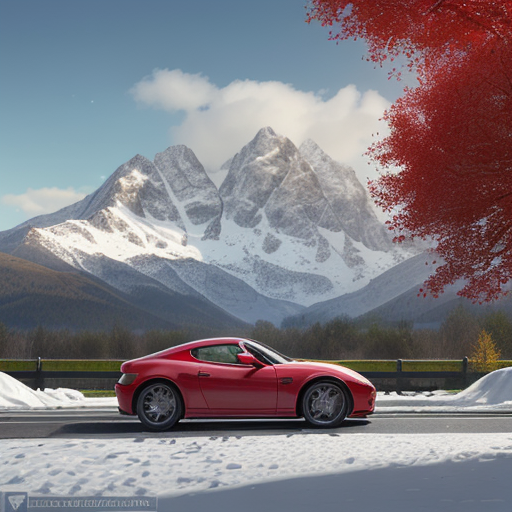

In [6]:
prompt = ("A red sports car parked beside a yellow bicycle under a large green tree, "
          "snow-covered mountains in the background, realistic photography, natural lighting, highly detailed")

def gen(pipe, prompt, steps=30, guidance=7.5, size=512, seed=12345):
    g = torch.Generator("cuda").manual_seed(seed)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t = time.perf_counter()
    img = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance,
               height=size, width=size, generator=g).images[0]
    torch.cuda.synchronize()
    return img, time.perf_counter() - t, torch.cuda.max_memory_allocated() / 1024**2

gen(pipe, prompt, steps=2)  # warm-up, not recorded
img, lat, mem = gen(pipe, prompt)
img.save(OUTPUT_DIR / "baseline_fp32.png")
print(f"FP32 | 30 steps | latency {lat:.2f}s | peak mem {mem:.0f} MB")
display(img)

In [8]:
pipe_kwargs = None; from diffusers.utils import logging as dl; dl.disable_progress_bar()

In [7]:
PROMPTS = [
 "A red sports car parked beside a yellow bicycle under a tree, with a mountain in the background.",
 "A wooden table with a blue ceramic vase, three red apples and an open book, photographed in natural light.",
 "A small white dog sitting on a green sofa, with a brown cat sleeping beside it.",
 "A futuristic city with flying vehicles, glass skyscrapers and people walking on a wet street at night.",
 "A woman wearing a red jacket standing to the left of a blue motorcycle, with a lake behind them.",
 "A wooden cabin surrounded by pine trees, snow-covered mountains in the background and a river flowing in front.",
 "A black laptop placed on a wooden desk, with a coffee cup on its right and a notebook on its left.",
 "A realistic garden containing yellow sunflowers, purple tulips and a small stone fountain.",
 "A modern living room with a grey sofa, a round coffee table and a large window overlooking a city.",
 "A golden retriever running on a beach while two birds fly above the ocean.",
 "A red umbrella leaning against a blue chair, both placed under a large tree in a quiet park.",
 "A glass bottle filled with orange juice placed behind a white plate containing two green pears and one sliced orange.",
]

def model_size_mb(pipe):
    n = 0
    for m in (pipe.unet, pipe.vae, pipe.text_encoder):
        n += sum(p.numel() * p.element_size() for p in m.parameters())
    return round(n / 1024**2, 1)

ROWS = []
def run_config(pipe, run_id, precision, steps, guidance=7.5, size=512, tag="E"):
    d = OUTPUT_DIR / run_id; d.mkdir(exist_ok=True)
    msize = model_size_mb(pipe)
    gen(pipe, PROMPTS[0], steps=2, size=size)  # warm-up
    for i, p in enumerate(PROMPTS, 1):
        img, lat, mem = gen(pipe, p, steps=steps, guidance=guidance, size=size)
        path = d / f"p{i:02d}.png"; img.save(path)
        ROWS.append(dict(model_id=MODEL_ID, run_id=run_id, precision=precision,
                         steps=steps, guidance_scale=guidance, height=size, width=size,
                         seed=12345, prompt_id=i, latency_seconds=round(lat, 3),
                         peak_allocated_mb=round(mem, 1), model_size_mb=msize,
                         image_path=str(path)))
    print(run_id, "done | median latency:",
          round(pd.DataFrame(ROWS).query("run_id==@run_id").latency_seconds.median(), 2), "s")

run_config(pipe, "E0_fp32_30", "fp32", 30)

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

E0_fp32_30 done | median latency: 15.0 s


In [9]:
del pipe; import gc; gc.collect(); torch.cuda.empty_cache()
pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, use_safetensors=True, safety_checker=None).to("cuda")
run_config(pipe, "E1_fp16_30", "fp16", 30)
run_config(pipe, "E2_fp16_15", "fp16", 15)
run_config(pipe, "E3_fp16_8", "fp16", 8)
pd.DataFrame(ROWS).to_csv("member4_metrics.csv", index=False)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

... (35 outputs left out)

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

E3_fp16_8 done | median latency: 1.47 s


In [11]:
import torch.nn.functional as F

@torch.inference_mode()
def clip_sim(prompt, img):
    x = cproc(text=[prompt], images=[img.convert("RGB")], return_tensors="pt",
              padding=True, truncation=True).to("cuda")
    out = cmodel(**x)
    t = F.normalize(out.text_embeds, dim=-1)
    i = F.normalize(out.image_embeds, dim=-1)
    return float((t * i).sum())

df = pd.DataFrame(ROWS)
df["clip_similarity"] = [clip_sim(PROMPTS[r.prompt_id - 1], Image.open(r.image_path))
                         for r in df.itertuples()]
df.to_csv("member4_metrics.csv", index=False)

summary = df.groupby("run_id").agg(
    precision=("precision", "first"), steps=("steps", "first"),
    median_latency_s=("latency_seconds", "median"),
    peak_mem_mb=("peak_allocated_mb", "max"),
    model_size_mb=("model_size_mb", "first"),
    clip_mean=("clip_similarity", "mean")).round(3)
base = summary.loc["E0_fp32_30"]
summary["latency_gain_%"] = ((base.median_latency_s - summary.median_latency_s) / base.median_latency_s * 100).round(1)
summary["memory_gain_%"] = ((base.peak_mem_mb - summary.peak_mem_mb) / base.peak_mem_mb * 100).round(1)
display(summary)


,precision,steps,median_latency_s,peak_mem_mb,model_size_mb,clip_mean,latency_gain_%,memory_gain_%
run_id,,,,,,,,
E0_fp32_30,fp32,30,15.003,4870.4,4067.4,0.361,0.0,0.0
E1_fp16_30,fp16,30,4.872,2675.8,2033.7,0.361,67.5,45.1
E2_fp16_15,fp16,15,2.518,2675.8,2033.7,0.356,83.2,45.1
E3_fp16_8,fp16,8,1.473,2675.8,2033.7,0.349,90.2,45.1


In [16]:
%pip install -q peft
import gc
from diffusers import LCMScheduler

SCORES = dict(zip(df.image_path, df.clip_similarity))   # keep existing CLIP scores
cmodel.to("cpu"); gc.collect(); torch.cuda.empty_cache()  # keep CLIP out of memory numbers

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, use_safetensors=True, safety_checker=None).to("cuda")
pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5")
pipe.fuse_lora()

run_config(pipe, "E4_lcm_4", "fp16+lcm-lora", 4, guidance=1.5)
run_config(pipe, "E5_lcm_6", "fp16+lcm-lora", 6, guidance=1.5)
run_config(pipe, "E6_lcm_4_384", "fp16+lcm-lora", 4, guidance=1.5, size=384)

# score only the new images
cmodel.to("cuda")
df = pd.DataFrame(ROWS)
df["clip_similarity"] = [SCORES.get(r.image_path) if r.image_path in SCORES
                         else clip_sim(PROMPTS[r.prompt_id - 1], Image.open(r.image_path))
                         for r in df.itertuples()]
df.to_csv("member4_metrics.csv", index=False)

summary = df.groupby("run_id").agg(
    precision=("precision", "first"), steps=("steps", "first"), size=("height", "first"),
    median_latency_s=("latency_seconds", "median"), peak_mem_mb=("peak_allocated_mb", "max"),
    clip_mean=("clip_similarity", "mean")).round(3)
base = summary.loc["E0_fp32_30"]
summary["latency_gain_%"] = ((base.median_latency_s - summary.median_latency_s) / base.median_latency_s * 100).round(1)
summary["memory_gain_%"] = ((base.peak_mem_mb - summary.peak_mem_mb) / base.peak_mem_mb * 100).round(1)
display(summary)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.
No LoRA keys associated to CLIPTextModel found with the prefix='t

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (35 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

E6_lcm_4_384 done | median latency: 0.58 s


,precision,steps,size,median_latency_s,peak_mem_mb,clip_mean,latency_gain_%,memory_gain_%
run_id,,,,,,,,
E0_fp32_30,fp32,30,512,15.003,4870.4,0.361,0.0,0.0
E1_fp16_30,fp16,30,512,4.872,2675.8,0.361,67.5,45.1
E2_fp16_15,fp16,15,512,2.518,2675.8,0.356,83.2,45.1
E3_fp16_8,fp16,8,512,1.473,2675.8,0.349,90.2,45.1
E4_lcm_4,fp16+lcm-lora,4,512,0.937,4891.1,0.334,93.8,-0.4
E5_lcm_6,fp16+lcm-lora,6,512,1.198,4891.1,0.332,92.0,-0.4
E6_lcm_4_384,fp16+lcm-lora,4,384,0.584,4624.4,0.329,96.1,5.1


GPU allocated now (MB): 4858
CLIP device: cuda:0
After cleanup (MB): 2656


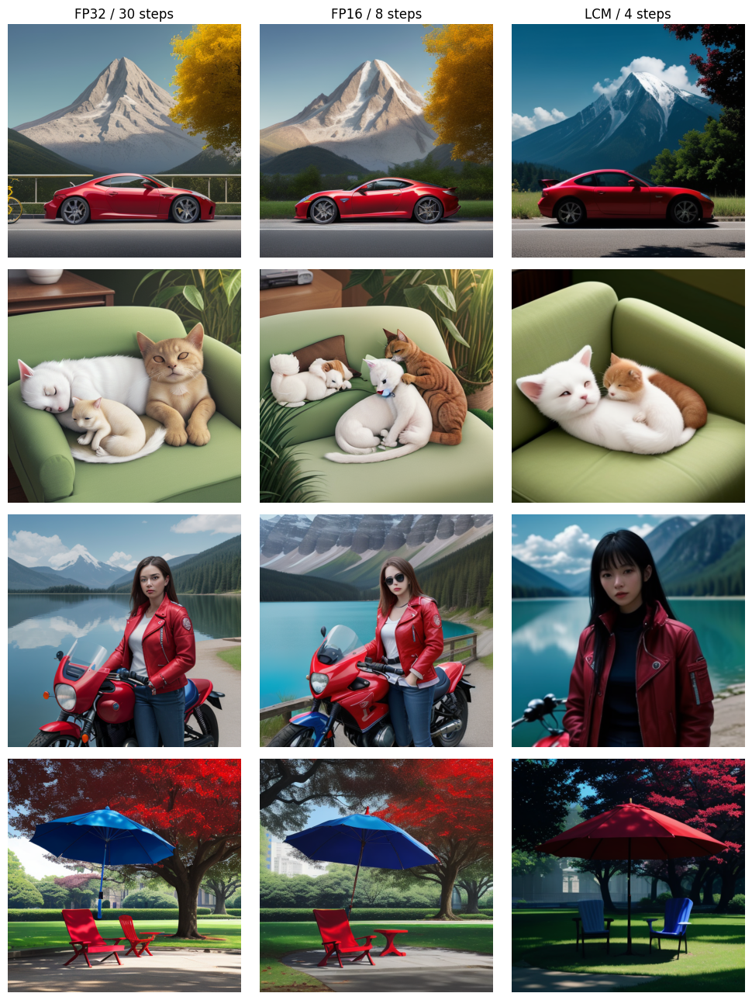

In [17]:
import gc, matplotlib.pyplot as plt
print("GPU allocated now (MB):", round(torch.cuda.memory_allocated()/1024**2))
print("CLIP device:", next(cmodel.parameters()).device)

# free everything, then reload a clean fused LCM pipeline and re-measure E4 only
try: del pipe
except NameError: pass
gc.collect(); torch.cuda.empty_cache()
print("After cleanup (MB):", round(torch.cuda.memory_allocated()/1024**2))

# visual grid: FP32 30 steps vs FP16 8 steps vs LCM 4 steps, prompts 1,3,5,11
ids = [1, 3, 5, 11]
runs = [("E0_fp32_30", "FP32 / 30 steps"), ("E3_fp16_8", "FP16 / 8 steps"), ("E4_lcm_4", "LCM / 4 steps")]
fig, ax = plt.subplots(len(ids), len(runs), figsize=(10, 13))
for r, pid in enumerate(ids):
    for c, (rid, name) in enumerate(runs):
        ax[r, c].imshow(Image.open(OUTPUT_DIR / rid / f"p{pid:02d}.png")); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(name)
plt.tight_layout(); plt.savefig("comparison_grid.png", dpi=120); plt.show()

In [18]:
import gc
from diffusers import LCMScheduler

SCORES = {r.image_path: r.clip_similarity for r in df.itertuples()
          if not r.run_id.startswith(("E4", "E5", "E6"))}
try: del pipe
except NameError: pass
gc.collect(); torch.cuda.empty_cache()
print("GPU allocated before load (MB):", round(torch.cuda.memory_allocated()/1024**2))  # expect ~0
cmodel.to("cpu")
ROWS[:] = [r for r in ROWS if not r["run_id"].startswith(("E4", "E5", "E6"))]

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, use_safetensors=True, safety_checker=None).to("cuda")
pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5")
pipe.fuse_lora(); pipe.unload_lora_weights()   # drop adapter copies after fusing

run_config(pipe, "E4_lcm_4", "fp16+lcm-lora", 4, guidance=1.5)
run_config(pipe, "E5_lcm_6", "fp16+lcm-lora", 6, guidance=1.5)
run_config(pipe, "E6_lcm_4_384", "fp16+lcm-lora", 4, guidance=1.5, size=384)

del pipe; gc.collect(); torch.cuda.empty_cache()
cmodel.to("cuda")
df = pd.DataFrame(ROWS)
df["clip_similarity"] = [SCORES.get(r.image_path) if r.image_path in SCORES
                         else clip_sim(PROMPTS[r.prompt_id - 1], Image.open(r.image_path))
                         for r in df.itertuples()]
df.to_csv("member4_metrics.csv", index=False)
summary = df.groupby("run_id").agg(
    steps=("steps", "first"), size=("height", "first"),
    median_latency_s=("latency_seconds", "median"), peak_mem_mb=("peak_allocated_mb", "max"),
    clip_mean=("clip_similarity", "mean")).round(3)
display(summary)

GPU allocated before load (MB): 2656


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.
No LoRA keys associated to CLIPTextModel found with the prefix='t

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

... (37 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

E6_lcm_4_384 done | median latency: 0.59 s


,steps,size,median_latency_s,peak_mem_mb,clip_mean
run_id,,,,,
E0_fp32_30,30,512,15.003,4870.4,0.361
E1_fp16_30,30,512,4.872,2675.8,0.361
E2_fp16_15,15,512,2.518,2675.8,0.356
E3_fp16_8,8,512,1.473,2675.8,0.349
E4_lcm_4,4,512,0.872,4754.0,0.334
E5_lcm_6,6,512,1.220,4754.0,0.332
E6_lcm_4_384,4,384,0.591,4487.2,0.329


In [15]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [1]:
import torch, time, gc, pandas as pd, torch.nn.functional as F
from pathlib import Path
from PIL import Image
from diffusers import StableDiffusionPipeline
from transformers import CLIPModel, CLIPProcessor

MODEL_ID = "Lykon/dreamshaper-8"
OUTPUT_DIR = Path("outputs")

PROMPTS = [
 "A red sports car parked beside a yellow bicycle under a tree, with a mountain in the background.",
 "A wooden table with a blue ceramic vase, three red apples and an open book, photographed in natural light.",
 "A small white dog sitting on a green sofa, with a brown cat sleeping beside it.",
 "A futuristic city with flying vehicles, glass skyscrapers and people walking on a wet street at night.",
 "A woman wearing a red jacket standing to the left of a blue motorcycle, with a lake behind them.",
 "A wooden cabin surrounded by pine trees, snow-covered mountains in the background and a river flowing in front.",
 "A black laptop placed on a wooden desk, with a coffee cup on its right and a notebook on its left.",
 "A realistic garden containing yellow sunflowers, purple tulips and a small stone fountain.",
 "A modern living room with a grey sofa, a round coffee table and a large window overlooking a city.",
 "A golden retriever running on a beach while two birds fly above the ocean.",
 "A red umbrella leaning against a blue chair, both placed under a large tree in a quiet park.",
 "A glass bottle filled with orange juice placed behind a white plate containing two green pears and one sliced orange.",
]

def gen(pipe, prompt, steps=30, guidance=7.5, size=512, seed=12345):
    g = torch.Generator("cuda").manual_seed(seed)
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t = time.perf_counter()
    img = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance,
               height=size, width=size, generator=g).images[0]
    torch.cuda.synchronize()
    return img, time.perf_counter() - t, torch.cuda.max_memory_allocated() / 1024**2

def model_size_mb(pipe):
    n = sum(p.numel() * p.element_size() for m in (pipe.unet, pipe.vae, pipe.text_encoder)
            for p in m.parameters())
    return round(n / 1024**2, 1)

df = pd.read_csv("member4_metrics.csv")
ROWS = df.drop(columns=["clip_similarity"]).to_dict("records")

def run_config(pipe, run_id, precision, steps, guidance=7.5, size=512):
    d = OUTPUT_DIR / run_id; d.mkdir(exist_ok=True)
    msize = model_size_mb(pipe)
    gen(pipe, PROMPTS[0], steps=2, size=size)  # warm-up
    for i, p in enumerate(PROMPTS, 1):
        img, lat, mem = gen(pipe, p, steps=steps, guidance=guidance, size=size)
        path = d / f"p{i:02d}.png"; img.save(path)
        ROWS.append(dict(model_id=MODEL_ID, run_id=run_id, precision=precision,
                         steps=steps, guidance_scale=guidance, height=size, width=size,
                         seed=12345, prompt_id=i, latency_seconds=round(lat, 3),
                         peak_allocated_mb=round(mem, 1), model_size_mb=msize,
                         image_path=str(path)))
    print(run_id, "done | median latency:",
          round(pd.DataFrame(ROWS).query("run_id==@run_id").latency_seconds.median(), 2), "s")

clip_id = "openai/clip-vit-base-patch32"
cproc = CLIPProcessor.from_pretrained(clip_id)
cmodel = CLIPModel.from_pretrained(clip_id).eval()   # stays on CPU for now

@torch.inference_mode()
def clip_sim(prompt, img):
    dev = next(cmodel.parameters()).device
    x = cproc(text=[prompt], images=[img.convert("RGB")], return_tensors="pt",
              padding=True, truncation=True).to(dev)
    out = cmodel(**x)
    return float((F.normalize(out.text_embeds, dim=-1) * F.normalize(out.image_embeds, dim=-1)).sum())

print("Recovered", len(ROWS), "rows from CSV")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Recovered 84 rows from CSV


In [2]:
import gc
from diffusers import LCMScheduler

SCORES = {r.image_path: r.clip_similarity for r in df.itertuples()
          if not r.run_id.startswith(("E4", "E5", "E6"))}
try: del pipe
except NameError: pass
gc.collect(); torch.cuda.empty_cache()
print("GPU allocated before load (MB):", round(torch.cuda.memory_allocated()/1024**2))  # expect ~0
cmodel.to("cpu")
ROWS[:] = [r for r in ROWS if not r["run_id"].startswith(("E4", "E5", "E6"))]

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, use_safetensors=True, safety_checker=None).to("cuda")
pipe.scheduler = LCMScheduler.from_config(pipe.scheduler.config)
pipe.load_lora_weights("latent-consistency/lcm-lora-sdv1-5")
pipe.fuse_lora(); pipe.unload_lora_weights()   # drop adapter copies after fusing

run_config(pipe, "E4_lcm_4", "fp16+lcm-lora", 4, guidance=1.5)
run_config(pipe, "E5_lcm_6", "fp16+lcm-lora", 6, guidance=1.5)
run_config(pipe, "E6_lcm_4_384", "fp16+lcm-lora", 4, guidance=1.5, size=384)

del pipe; gc.collect(); torch.cuda.empty_cache()
cmodel.to("cuda")
df = pd.DataFrame(ROWS)
df["clip_similarity"] = [SCORES.get(r.image_path) if r.image_path in SCORES
                         else clip_sim(PROMPTS[r.prompt_id - 1], Image.open(r.image_path))
                         for r in df.itertuples()]
df.to_csv("member4_metrics.csv", index=False)
summary = df.groupby("run_id").agg(
    steps=("steps", "first"), size=("height", "first"),
    median_latency_s=("latency_seconds", "median"), peak_mem_mb=("peak_allocated_mb", "max"),
    clip_mean=("clip_similarity", "mean")).round(3)
display(summary)

GPU allocated before load (MB): 0


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
The config attributes {'skip_prk_steps': True} were passed to LCMScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.
No LoRA keys associated to CLIPTextModel found with the prefix='t

  0%|          | 0/2 [00:00<?, ?it/s]

... (38 outputs left out)

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

E6_lcm_4_384 done | median latency: 0.58 s


,steps,size,median_latency_s,peak_mem_mb,clip_mean
run_id,,,,,
E0_fp32_30,30,512,15.003,4870.4,0.361
E1_fp16_30,30,512,4.872,2675.8,0.361
E2_fp16_15,15,512,2.518,2675.8,0.356
E3_fp16_8,8,512,1.473,2675.8,0.349
E4_lcm_4,4,512,0.876,2675.9,0.334
E5_lcm_6,6,512,1.166,2675.9,0.332
E6_lcm_4_384,4,384,0.581,2409.2,0.329


In [3]:
PROFILE_RUNS = {"LOW": "E6_lcm_4_384", "BALANCED": "E2_fp16_15", "QUALITY": "E1_fp16_30"}
ORDER = ["QUALITY", "BALANCED", "LOW"]

stats = df.groupby("run_id").agg(steps=("steps","first"), size=("height","first"),
        precision=("precision","first"), latency=("latency_seconds","median"),
        mem=("peak_allocated_mb","max"), clip=("clip_similarity","mean"))

def choose_profile(requested, free_mem_mb, max_latency_s=None):
    """Rule-based controller: only uses configs already benchmarked."""
    prof, msgs = requested, []
    while True:
        s = stats.loc[PROFILE_RUNS[prof]]
        too_big  = s.mem > free_mem_mb * 0.9
        too_slow = max_latency_s is not None and s.latency > max_latency_s
        if not (too_big or too_slow) or prof == "LOW":
            if too_big or too_slow:
                msgs.append("WARNING: even LOW exceeds the budget; using LOW anyway")
            break
        nxt = ORDER[ORDER.index(prof) + 1]
        msgs.append(f"{prof} -> {nxt} ({'memory' if too_big else 'latency'} budget exceeded)")
        prof = nxt
    s = stats.loc[PROFILE_RUNS[prof]]
    return dict(profile=prof, run_id=PROFILE_RUNS[prof], precision=s.precision, steps=int(s.steps),
                size=int(s["size"]), est_latency_s=round(s.latency, 2), est_mem_mb=round(s.mem),
                notes="; ".join(msgs) or "requested profile fits")

free_now = torch.cuda.mem_get_info()[0] / 1024**2
print("Free GPU memory now (MB):", round(free_now))
tests = [("QUALITY", 8000, None), ("QUALITY", 8000, 3.0), ("QUALITY", 8000, 1.0),
         ("BALANCED", 8000, None), ("BALANCED", 1500, None), ("LOW", 8000, None)]
rows = [dict(requested=r, free_mb=m, max_lat=l, **choose_profile(r, m, l)) for r, m, l in tests]
display(pd.DataFrame(rows))

Free GPU memory now (MB): 14140


,requested,free_mb,max_lat,profile,run_id,precision,steps,size,est_latency_s,est_mem_mb,notes
0,QUALITY,8000,NaN,QUALITY,E1_fp16_30,fp16,30,512,4.87,2676,requested profile fits
1,QUALITY,8000,3.0,BALANCED,E2_fp16_15,fp16,15,512,2.52,2676,QUALITY -> BALANCED (latency budget exceeded)
2,QUALITY,8000,1.0,LOW,E6_lcm_4_384,fp16+lcm-lora,4,384,0.58,2409,QUALITY -> BALANCED (latency budget exceeded);...
3,BALANCED,8000,NaN,BALANCED,E2_fp16_15,fp16,15,512,2.52,2676,requested profile fits
4,BALANCED,1500,NaN,LOW,E6_lcm_4_384,fp16+lcm-lora,4,384,0.58,2409,BALANCED -> LOW (memory budget exceeded); WARN...
5,LOW,8000,NaN,LOW,E6_lcm_4_384,fp16+lcm-lora,4,384,0.58,2409,requested profile fits


In [4]:
%%writefile cv_postprocess.py
import cv2, numpy as np
from PIL import Image

def quality_metrics(img):
    rgb = np.array(img.convert("RGB")); gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 100, 200)
    return dict(sharpness=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                brightness_mean=float(gray.mean()), contrast_std=float(gray.std()),
                edge_density=float((edges > 0).mean()))

def artifact_flags(m, blur_thresh=100.0):
    f = []
    if m["sharpness"] < blur_thresh: f.append("blurry")
    if m["contrast_std"] < 35: f.append("low_contrast")
    if m["brightness_mean"] < 60: f.append("dark")
    if m["brightness_mean"] > 200: f.append("overexposed")
    return f

def postprocess(img, target_size=None, blur_thresh=100.0):
    """PIL in -> (PIL out, metrics). Heuristic checks, not a full artifact detector."""
    out = img.convert("RGB")
    if target_size and out.size != (target_size, target_size):
        out = out.resize((target_size, target_size), Image.Resampling.LANCZOS)
    before = quality_metrics(out)
    rgb = np.array(out)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)                       # colour/contrast
    lab[..., 0] = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(8, 8)).apply(lab[..., 0])
    rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    rgb = cv2.bilateralFilter(rgb, d=5, sigmaColor=40, sigmaSpace=40)  # edge-aware denoise
    sharpened = False
    if quality_metrics(Image.fromarray(rgb))["sharpness"] < blur_thresh:  # only if blurry
        soft = cv2.GaussianBlur(rgb, (0, 0), 1.2)
        rgb = cv2.addWeighted(rgb, 1.4, soft, -0.4, 0); sharpened = True
    out2 = Image.fromarray(rgb)
    after = quality_metrics(out2)
    return out2, dict(before=before, after=after, flags_before=artifact_flags(before, blur_thresh),
                      flags_after=artifact_flags(after, blur_thresh), sharpened=sharpened)

Writing cv_postprocess.py


,prompt_id,sharp_before,sharp_after,contrast_before,contrast_after,bright_before,bright_after,flags_before,sharpened,clip_before,clip_after,kept_processed
0,1,196.1,334.5,53.3,58.2,63.2,73.8,-,False,0.2936,0.2707,False
1,2,134.5,164.6,76.2,72.5,75.8,84.0,-,False,0.3457,0.3485,True
2,3,109.9,134.3,85.4,80.1,121.8,125.6,-,False,0.3427,0.3299,False
3,4,80.1,147.7,39.1,49.0,35.2,50.0,"blurry,dark",False,0.3547,0.3475,False
4,5,59.8,163.6,61.8,59.9,75.0,83.0,blurry,True,0.3229,0.3282,True
5,6,345.8,596.8,53.9,57.3,77.6,92.8,-,False,0.3065,0.2956,False
6,7,131.3,195.1,86.4,83.9,112.0,117.9,-,False,0.2955,0.2979,True
7,8,150.9,269.3,46.5,58.6,36.4,51.8,dark,False,0.3268,0.3279,True
8,9,280.1,328.6,81.6,77.1,116.9,125.0,-,False,0.3434,0.3388,False
9,10,143.5,210.3,59.6,61.5,164.6,154.5,-,False,0.3310,0.3372,True


Mean CLIP before/after: 0.3289 0.3251 | processed kept: 6 of 12


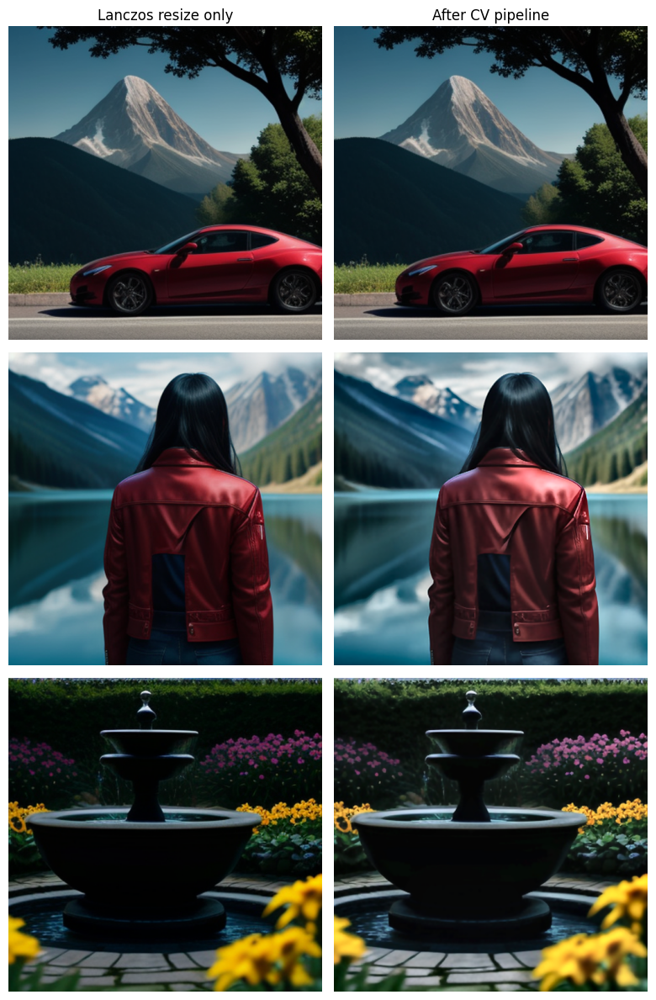

In [5]:
import importlib, matplotlib.pyplot as plt
import cv_postprocess; importlib.reload(cv_postprocess)
from cv_postprocess import postprocess

FINAL = OUTPUT_DIR / "cv_final"; FINAL.mkdir(exist_ok=True)
rows = []
for i, p in enumerate(PROMPTS, 1):
    raw = Image.open(OUTPUT_DIR / "E6_lcm_4_384" / f"p{i:02d}.png")
    base = raw.convert("RGB").resize((512, 512), Image.Resampling.LANCZOS)   # resize only
    proc, m = postprocess(raw, target_size=512)
    c0, c1 = clip_sim(p, base), clip_sim(p, proc)
    keep = c1 >= c0 - 0.002                       # CLIP guard: keep original if score drops
    (proc if keep else base).save(FINAL / f"p{i:02d}.png")
    rows.append(dict(prompt_id=i, sharp_before=round(m["before"]["sharpness"], 1),
        sharp_after=round(m["after"]["sharpness"], 1),
        contrast_before=round(m["before"]["contrast_std"], 1), contrast_after=round(m["after"]["contrast_std"], 1),
        bright_before=round(m["before"]["brightness_mean"], 1), bright_after=round(m["after"]["brightness_mean"], 1),
        flags_before=",".join(m["flags_before"]) or "-", sharpened=m["sharpened"],
        clip_before=round(c0, 4), clip_after=round(c1, 4), kept_processed=keep))
cv = pd.DataFrame(rows); cv.to_csv("cv_metrics.csv", index=False); display(cv)
print("Mean CLIP before/after:", cv.clip_before.mean().round(4), cv.clip_after.mean().round(4),
      "| processed kept:", int(cv.kept_processed.sum()), "of 12")

fig, ax = plt.subplots(3, 2, figsize=(8, 12))
for r, pid in enumerate([1, 5, 8]):
    raw = Image.open(OUTPUT_DIR / "E6_lcm_4_384" / f"p{pid:02d}.png").resize((512, 512), Image.Resampling.LANCZOS)
    ax[r, 0].imshow(raw); ax[r, 1].imshow(Image.open(FINAL / f"p{pid:02d}.png"))
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
ax[0, 0].set_title("Lanczos resize only"); ax[0, 1].set_title("After CV pipeline")
plt.tight_layout(); plt.savefig("cv_before_after.png", dpi=120); plt.show()

In [6]:
print("Mean CLIP of delivered images:", round(cv.apply(lambda r: r.clip_after if r.kept_processed else r.clip_before, axis=1).mean(), 4))

Mean CLIP of delivered images: 0.3309


In [7]:
import gc
cmodel.to("cpu"); gc.collect(); torch.cuda.empty_cache()
print("GPU allocated before load (MB):", round(torch.cuda.memory_allocated()/1024**2))  # expect ~0

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, use_safetensors=True, safety_checker=None).to("cuda")
SEEDS = [12345, 101, 202, 303]
d = OUTPUT_DIR / "bestofN"; d.mkdir(exist_ok=True)
gen(pipe, PROMPTS[0], steps=2)   # warm-up
cands = []
for i, p in enumerate(PROMPTS, 1):
    for s in SEEDS:
        img, lat, mem = gen(pipe, p, steps=15, seed=s)
        path = d / f"p{i:02d}_s{s}.png"; img.save(path)
        cands.append(dict(prompt_id=i, seed=s, path=str(path), latency=lat, mem=mem))
del pipe; gc.collect(); torch.cuda.empty_cache()

cmodel.to("cuda")
cd = pd.DataFrame(cands)
cd["clip"] = [clip_sim(PROMPTS[r.prompt_id - 1], Image.open(r.path)) for r in cd.itertuples()]
cd.to_csv("bestofN_candidates.csv", index=False)

best = cd.loc[cd.groupby("prompt_id").clip.idxmax()]
single = cd[cd.seed == 12345]
print(f"Single seed, 15 steps : CLIP {single.clip.mean():.4f} | latency {single.latency.median():.2f}s")
print(f"Best-of-4,  15 steps  : CLIP {best.clip.mean():.4f} | latency {cd.groupby('prompt_id').latency.sum().median():.2f}s | peak mem {cd.mem.max():.0f} MB")
print("Reference: FP16 30 steps single seed: CLIP 0.361 | 4.87s")

fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, r in zip(ax, cd[cd.prompt_id == 11].itertuples()):
    a.imshow(Image.open(r.path)); a.axis("off")
    a.set_title(f"seed {r.seed} | CLIP {r.clip:.3f}" + ("  <- picked" if r.clip == cd[cd.prompt_id == 11].clip.max() else ""))
plt.tight_layout(); plt.savefig("bestofN_prompt11.png", dpi=110); plt.show()

GPU allocated before load (MB): 8


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/2 [00:00<?, ?it/s]

... (45 outputs left out)

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

AttributeError: 'function' object has no attribute 'mean'

Single seed, 15 steps : CLIP 0.3560 | latency 2.55s
Best-of-4,  15 steps  : CLIP 0.3726 | latency 10.20s | peak mem 2676 MB
Reference: FP16 30 steps single seed: CLIP 0.361 | 4.87s


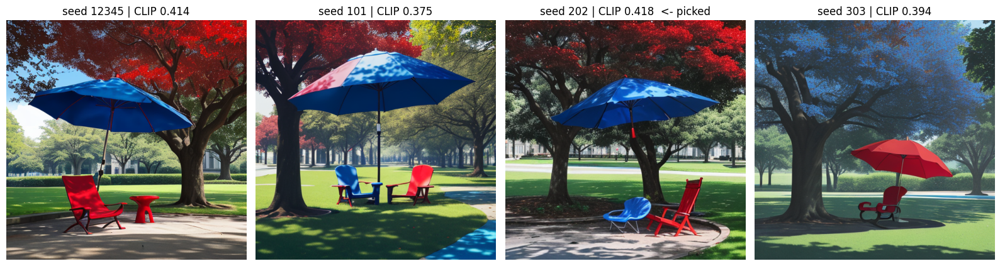

In [8]:
cd = cd.rename(columns={"clip": "clip_score"})
cd.to_csv("bestofN_candidates.csv", index=False)

best = cd.loc[cd.groupby("prompt_id")["clip_score"].idxmax()]
single = cd[cd.seed == 12345]
print(f"Single seed, 15 steps : CLIP {single['clip_score'].mean():.4f} | latency {single['latency'].median():.2f}s")
print(f"Best-of-4,  15 steps  : CLIP {best['clip_score'].mean():.4f} | latency {cd.groupby('prompt_id')['latency'].sum().median():.2f}s | peak mem {cd['mem'].max():.0f} MB")
print("Reference: FP16 30 steps single seed: CLIP 0.361 | 4.87s")

p11 = cd[cd.prompt_id == 11]
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, (_, r) in zip(ax, p11.iterrows()):
    a.imshow(Image.open(r["path"])); a.axis("off")
    a.set_title(f"seed {int(r['seed'])} | CLIP {r['clip_score']:.3f}" + ("  <- picked" if r["clip_score"] == p11["clip_score"].max() else ""))
plt.tight_layout(); plt.savefig("bestofN_prompt11.png", dpi=110); plt.show()

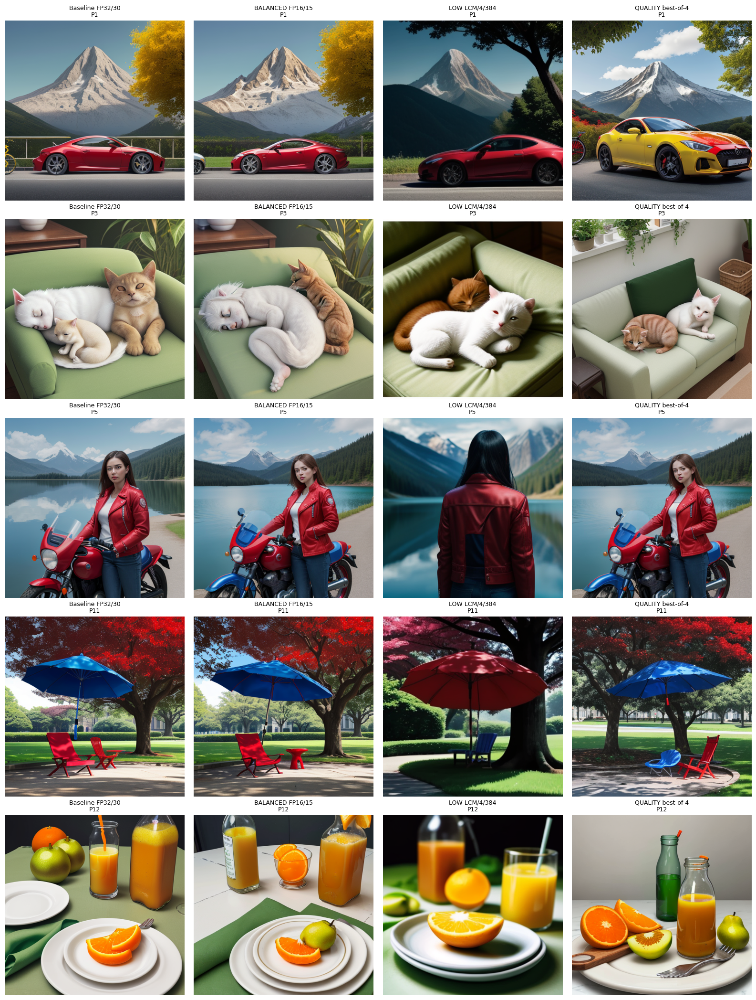

TypeError: type method doesn't define __round__ method

In [9]:
cfgs = [("Baseline FP32/30", "E0_fp32_30"), ("BALANCED FP16/15", "E2_fp16_15"),
        ("LOW LCM/4/384", "E6_lcm_4_384"), ("QUALITY best-of-4", None)]
ids = [1, 3, 5, 11, 12]
bpath = {int(r.prompt_id): r.path for r in best.itertuples()}

fig, ax = plt.subplots(len(ids), 4, figsize=(16, 4.2 * len(ids)))
for r, pid in enumerate(ids):
    for c, (name, rid) in enumerate(cfgs):
        p = bpath[pid] if rid is None else OUTPUT_DIR / rid / f"p{pid:02d}.png"
        ax[r, c].imshow(Image.open(p)); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name}\nP{pid}", fontsize=9)
plt.tight_layout(); plt.savefig("rubric_sheet.png", dpi=80); plt.show()

rub = pd.DataFrame([dict(prompt_id=pid, config=name, objects_1to5="", attributes_1to5="",
                         spatial_1to5="", realism_1to5="") for pid in ids for name, _ in cfgs])
rub.to_csv("manual_rubric.csv", index=False)

# final comparison table from measured data
rows = []
for name, rid in cfgs[:3]:
    s = stats.loc[rid]; rows.append(dict(config=name, run_id=rid, precision=s.precision, steps=int(s.steps),
        size=int(s["size"]), latency_s=round(s.latency, 2), peak_mem_mb=round(s.mem), clip=round(s.clip, 3)))
s = stats.loc["E1_fp16_30"]; rows.insert(1, dict(config="FP16/30 (reference)", run_id="E1_fp16_30", precision="fp16",
    steps=30, size=512, latency_s=round(s.latency, 2), peak_mem_mb=round(s.mem), clip=round(s.clip, 3)))
rows.append(dict(config="QUALITY best-of-4", run_id="bestofN", precision="fp16", steps="15x4", size=512,
    latency_s=round(cd.groupby("prompt_id")["latency"].sum().median(), 2), peak_mem_mb=round(cd["mem"].max()),
    clip=round(best["clip_score"].mean(), 3)))
final = pd.DataFrame(rows)
b = final.iloc[0]
final["latency_gain_%"] = ((b.latency_s - final.latency_s) / b.latency_s * 100).round(1)
final["memory_gain_%"] = ((b.peak_mem_mb - final.peak_mem_mb) / b.peak_mem_mb * 100).round(1)
final.to_csv("final_comparison.csv", index=False); display(final)

In [10]:
stats = stats.rename(columns={"clip": "clip_mean"})

def row(name, rid):
    s = stats.loc[rid]
    return dict(config=name, run_id=rid, precision=s["precision"], steps=int(s["steps"]),
                size=int(s["size"]), latency_s=round(float(s["latency"]), 2),
                peak_mem_mb=round(float(s["mem"])), clip=round(float(s["clip_mean"]), 3))

rows = [row("Baseline FP32/30", "E0_fp32_30"),
        row("FP16/30 (reference)", "E1_fp16_30"),
        row("BALANCED FP16/15", "E2_fp16_15"),
        row("LOW LCM/4/384", "E6_lcm_4_384"),
        dict(config="QUALITY best-of-4", run_id="bestofN", precision="fp16", steps="15x4", size=512,
             latency_s=round(float(cd.groupby("prompt_id")["latency"].sum().median()), 2),
             peak_mem_mb=round(float(cd["mem"].max())),
             clip=round(float(best["clip_score"].mean()), 3))]

final = pd.DataFrame(rows)
b = final.iloc[0]
final["latency_gain_%"] = ((b.latency_s - final.latency_s) / b.latency_s * 100).round(1)
final["memory_gain_%"] = ((b.peak_mem_mb - final.peak_mem_mb) / b.peak_mem_mb * 100).round(1)
final.to_csv("final_comparison.csv", index=False)
display(final)

,config,run_id,precision,steps,size,latency_s,peak_mem_mb,clip,latency_gain_%,memory_gain_%
0,Baseline FP32/30,E0_fp32_30,fp32,30,512,15.00,4870,0.361,0.0,0.0
1,FP16/30 (reference),E1_fp16_30,fp16,30,512,4.87,2676,0.361,67.5,45.1
2,BALANCED FP16/15,E2_fp16_15,fp16,15,512,2.52,2676,0.356,83.2,45.1
3,LOW LCM/4/384,E6_lcm_4_384,fp16+lcm-lora,4,384,0.58,2409,0.329,96.1,50.5
4,QUALITY best-of-4,bestofN,fp16,15x4,512,10.20,2676,0.373,32.0,45.1


In [11]:
stats.loc["bestofN"] = dict(steps=15, size=512, precision="fp16",
                            latency=float(cd.groupby("prompt_id")["latency"].sum().median()),
                            mem=float(cd["mem"].max()), clip_mean=float(best["clip_score"].mean()))
PROFILE_RUNS["QUALITY"] = "bestofN"
print(pd.DataFrame([choose_profile("QUALITY", 8000), choose_profile("QUALITY", 1500)])[["profile","notes"]])

   profile                                              notes
0  QUALITY                             requested profile fits
1      LOW  QUALITY -> BALANCED (memory budget exceeded); ...


In [12]:
%pip install -q gradio
import gradio as gr, gc, importlib
from diffusers import LCMScheduler
import cv_postprocess; importlib.reload(cv_postprocess)
from cv_postprocess import postprocess

cmodel.to("cpu"); gc.collect(); torch.cuda.empty_cache()   # keep CLIP off the GPU
CUR = {"kind": None, "pipe": None}
LOG = []

def get_pipe(kind):
    if CUR["kind"] == kind: return CUR["pipe"], 0.0
    CUR["pipe"] = None; CUR["kind"] = None; gc.collect(); torch.cuda.empty_cache()
    t = time.perf_counter()
    p = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.float16,
            use_safetensors=True, safety_checker=None).to("cuda")
    if kind == "lcm":
        p.scheduler = LCMScheduler.from_config(p.scheduler.config)
        p.load_lora_weights("latent-consistency/lcm-lora-sdv1-5"); p.fuse_lora(); p.unload_lora_weights()
    p.set_progress_bar_config(disable=True)
    CUR.update(kind=kind, pipe=p)
    return p, time.perf_counter() - t

def run_profile(prof, prompt):
    if prof == "LOW":
        pipe, load_s = get_pipe("lcm")
        img, lat, mem = gen(pipe, prompt, steps=4, guidance=1.5, size=384)
        return img, lat, mem, load_s, "LCM-LoRA, 4 steps, 384px"
    pipe, load_s = get_pipe("fp16")
    if prof == "BALANCED":
        img, lat, mem = gen(pipe, prompt, steps=15, guidance=7.5, size=512)
        return img, lat, mem, load_s, "FP16, 15 steps, 512px"
    cands, lat, mem = [], 0.0, 0.0
    for s in [12345, 101, 202, 303]:
        im, l, m = gen(pipe, prompt, steps=15, guidance=7.5, size=512, seed=s)
        cands.append(im); lat += l; mem = max(mem, m)
    scores = [clip_sim(prompt, im) for im in cands]
    return cands[scores.index(max(scores))], lat, mem, load_s, "FP16, best-of-4 (CLIP-selected), 15 steps, 512px"

def generate(prompt, profile, free_mb, use_cv):
    plan = choose_profile(profile, free_mb)
    prof, notes = plan["profile"], plan["notes"]
    try:
        img, lat, mem, load_s, desc = run_profile(prof, prompt)
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        prof, notes = "LOW", notes + "; OOM -> retried with LOW"
        img, lat, mem, load_s, desc = run_profile("LOW", prompt)
    base = img.convert("RGB").resize((512, 512), Image.Resampling.LANCZOS)
    final, cv_note = base, "CV off"
    if use_cv:
        proc, m = postprocess(img, target_size=512)
        c0, c1 = clip_sim(prompt, base), clip_sim(prompt, proc)
        keep = c1 >= c0 - 0.002
        final = proc if keep else base
        cv_note = f"CV {'applied' if keep else 'rejected by CLIP guard'} (CLIP {c0:.3f} -> {c1:.3f})"
    clip_final = clip_sim(prompt, final)
    LOG.append(dict(prompt=prompt, requested=profile, used=prof, config=desc, latency_s=round(lat, 2),
                    peak_mem_mb=round(mem), clip=round(clip_final, 3), notes=notes))
    pd.DataFrame(LOG).to_csv("demo_log.csv", index=False)
    info = (f"**Profile used:** {prof} (requested {profile})  \n**Config:** {desc}  \n"
            f"**Generation time:** {lat:.2f} s (model load {load_s:.1f} s, not included)  \n"
            f"**Peak GPU memory:** {mem:.0f} MB  \n**CLIP similarity:** {clip_final:.3f}  \n"
            f"**Controller:** {notes}  \n**Post-processing:** {cv_note}")
    return final, info

demo = gr.Interface(
    fn=generate,
    inputs=[gr.Textbox(label="Prompt", value=PROMPTS[10]),
            gr.Radio(["LOW", "BALANCED", "QUALITY"], value="BALANCED", label="Compute profile"),
            gr.Slider(1500, 14000, value=8000, step=100, label="Available GPU memory budget (MB)"),
            gr.Checkbox(value=True, label="Apply classical CV enhancement")],
    outputs=[gr.Image(type="pil", label="Result"), gr.Markdown()],
    title="LiteGen AI - resource-aware text-to-image (browser demo on a Colab GPU)")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://09f84ee6507a6927b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


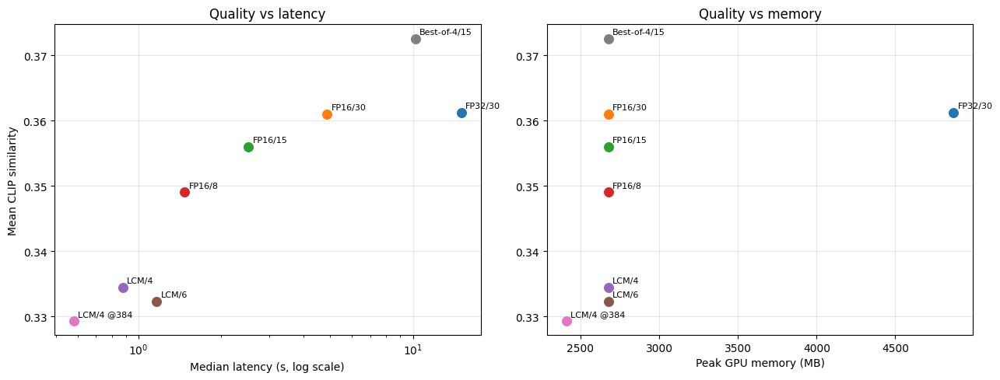

In [13]:
import matplotlib.pyplot as plt
names = {"E0_fp32_30": "FP32/30", "E1_fp16_30": "FP16/30", "E2_fp16_15": "FP16/15", "E3_fp16_8": "FP16/8",
         "E4_lcm_4": "LCM/4", "E5_lcm_6": "LCM/6", "E6_lcm_4_384": "LCM/4 @384", "bestofN": "Best-of-4/15"}
d = stats.loc[list(names)].copy()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for rid, r in d.iterrows():
    ax[0].scatter(r.latency, r.clip_mean, s=70); ax[0].annotate(names[rid], (r.latency, r.clip_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[1].scatter(r.mem, r.clip_mean, s=70); ax[1].annotate(names[rid], (r.mem, r.clip_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax[0].set_xlabel("Median latency (s, log scale)"); ax[0].set_xscale("log"); ax[0].set_ylabel("Mean CLIP similarity"); ax[0].set_title("Quality vs latency")
ax[1].set_xlabel("Peak GPU memory (MB)"); ax[1].set_title("Quality vs memory")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("quality_vs_cost.png", dpi=130); plt.show()

In [14]:
from transformers import CLIPTokenizer, CLIPTextModel
tok = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer")
te = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder").eval()
p = PROMPTS[4]
ids = tok(p, padding="max_length", max_length=tok.model_max_length, truncation=True, return_tensors="pt")
with torch.inference_mode():
    emb = te(ids.input_ids).last_hidden_state
print("Prompt:", p)
print("Tokens:", tok.convert_ids_to_tokens(ids.input_ids[0][:ids.attention_mask[0].sum()]))
print("Token count:", int(ids.attention_mask[0].sum()), "of", tok.model_max_length)
print("Embedding shape:", tuple(emb.shape), "-> fed to the UNet via cross-attention")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Prompt: A woman wearing a red jacket standing to the left of a blue motorcycle, with a lake behind them.
Tokens: ['<|startoftext|>', 'a</w>', 'woman</w>', 'wearing</w>', 'a</w>', 'red</w>', 'jacket</w>', 'standing</w>', 'to</w>', 'the</w>', 'left</w>', 'of</w>', 'a</w>', 'blue</w>', 'motorcycle</w>', ',</w>', 'with</w>', 'a</w>', 'lake</w>', 'behind</w>', 'them</w>', '.</w>', '<|endoftext|>']
Token count: 23 of 77
Embedding shape: (1, 77, 768) -> fed to the UNet via cross-attention


In [15]:
import json, os, zipfile
cfg = {"model_id": MODEL_ID, "gpu": "Tesla T4 (14.56 GB)", "seed": 12345,
       "profiles": {"LOW": "LCM-LoRA, 4 steps, 384px, FP16",
                    "BALANCED": "FP16, 15 steps, 512px",
                    "QUALITY": "FP16, best-of-4 x 15 steps (CLIP-selected), 512px"},
       "results": final.to_dict("records")}
json.dump(cfg, open("best_config.json", "w"), indent=2, default=str)

readme = f"""# Member 4: DreamShaper 8 adaptive text-to-image + CV
Measured on a Tesla T4. Not measured on a phone.

## Results (12 prompts, seed 12345, warm-up, median latency)
{final.to_markdown(index=False)}

## Mobile resource requirements (T4 measurements)
FP32: 4,067 MB weights / 4,870 MB peak. FP16: 2,034 / 2,676 MB. LOW (LCM, 384px): 2,034 / 2,409 MB.
Even LOW needs about 2.4 GB, so phones would need INT8 or a smaller architecture. Not done.

## What we did
FP16, fewer steps, LCM-LoRA and 384px as optimizations. CLIP similarity for alignment.
Rule-based controller (LOW / BALANCED / QUALITY) with memory and latency fallback.
CV post-processing (resize, CLAHE, bilateral denoise, conditional sharpen) kept only if CLIP does not drop by more than 0.002.
Delivered CLIP {cv.apply(lambda r: r.clip_after if r.kept_processed else r.clip_before, axis=1).mean():.4f} vs 0.3289 resize-only; processed kept in {int(cv.kept_processed.sum())}/12.
Prompt encoding: CLIP tokenizer + text encoder, 77 tokens, cross-attention conditioning.

## Honest limitations
- Adaptation: fused published LCM-LoRA weights and switched sampler to LCM. No training was performed by us. Fine-tuning is future work.
- QUALITY CLIP (0.373) is best-of-4 chosen by CLIP, so it is optimistic. Fair reference is FP16/30 at 0.361.
- CLIP misses colour and spatial errors; manual rubric covers prompts 5, 11, 12 only.
- Quality drops with fewer steps (CLIP 0.361 -> 0.349 at 8 steps, 0.334 with LCM).
- FID not computed (no reference dataset). Quantization below FP16, pruning and distillation not done.
- Smaller-architecture (Tiny-SD) and DPMSolver comparisons: not completed here.
- Demo runs on a Colab GPU with a temporary public link.
"""
open("README_M4.md", "w").write(readme)

files = ["README_M4.md","best_config.json","member4_metrics.csv","cv_metrics.csv","final_comparison.csv",
         "bestofN_candidates.csv","manual_rubric.csv","cv_postprocess.py","comparison_grid.png",
         "rubric_sheet.png","quality_vs_cost.png","cv_before_after.png","bestofN_prompt11.png"]
with zipfile.ZipFile("member4_submission.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        if os.path.exists(f): z.write(f)
        else: print("missing:", f)
    for f in sorted(os.listdir("outputs/cv_final")): z.write(f"outputs/cv_final/{f}")
print("zip size MB:", round(os.path.getsize("member4_submission.zip")/1024**2, 1))

zip size MB: 11.5


In [16]:
import numpy as np
pv = df.pivot(index="prompt_id", columns="run_id", values="clip_similarity")
pv["lcm384_drop"] = pv["E1_fp16_30"] - pv["E6_lcm_4_384"]
print(pv[["E0_fp32_30","E1_fp16_30","E2_fp16_15","E3_fp16_8","E6_lcm_4_384","lcm384_drop"]].round(3))

def ci(x, n=2000):
    x = np.asarray(x); b = [np.random.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(b, [2.5, 97.5]).round(3)
for a, b in [("E0_fp32_30","E1_fp16_30"), ("E1_fp16_30","E2_fp16_15"), ("E1_fp16_30","E6_lcm_4_384")]:
    d = pv[a] - pv[b]; print(f"{a} - {b}: mean {d.mean():.3f}, 95% CI {ci(d)}")

run_id     E0_fp32_30  E1_fp16_30  E2_fp16_15  E3_fp16_8  E6_lcm_4_384  \
prompt_id                                                                
1               0.398       0.400       0.308      0.303         0.294   
2               0.382       0.383       0.377      0.378         0.346   
3               0.355       0.351       0.350      0.334         0.342   
4               0.330       0.330       0.336      0.333         0.355   
5               0.382       0.382       0.400      0.398         0.324   
6               0.333       0.332       0.328      0.330         0.306   
7               0.319       0.326       0.302      0.266         0.296   
8               0.394       0.396       0.405      0.385         0.327   
9               0.349       0.350       0.370      0.347         0.344   
10              0.362       0.362       0.357      0.370         0.332   
11              0.404       0.401       0.414      0.410         0.395   
12              0.326       0.317     

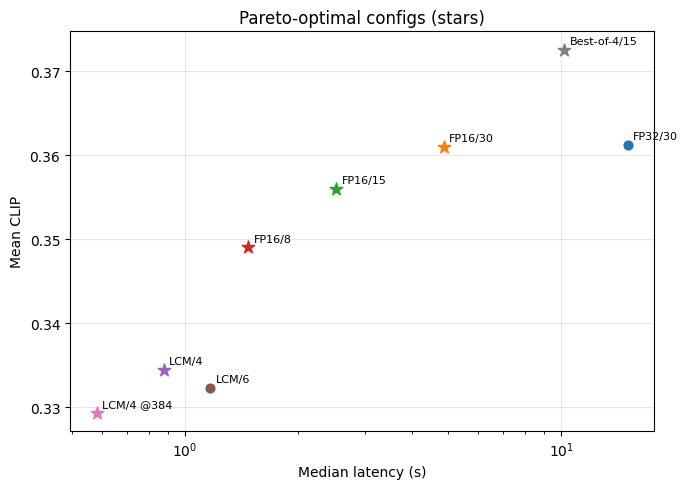

Pareto: ['FP16/30', 'FP16/15', 'FP16/8', 'LCM/4', 'LCM/4 @384', 'Best-of-4/15']


In [17]:
import matplotlib.pyplot as plt
d = stats.loc[list(names)].copy()
pareto = [r for r, x in d.iterrows() if not any((o.latency <= x.latency and o.clip_mean >= x.clip_mean and (o.latency < x.latency or o.clip_mean > x.clip_mean)) for _, o in d.iterrows())]
fig, ax = plt.subplots(figsize=(7,5))
for r, x in d.iterrows():
    ax.scatter(x.latency, x.clip_mean, s=90 if r in pareto else 40, marker="*" if r in pareto else "o")
    ax.annotate(names[r], (x.latency, x.clip_mean), fontsize=8, xytext=(4,4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("Median latency (s)"); ax.set_ylabel("Mean CLIP"); ax.set_title("Pareto-optimal configs (stars)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("pareto.png", dpi=130); plt.show(); print("Pareto:", [names[r] for r in pareto])